# San Francisco Metro BART Project

### Project Overview

This project analyzes San Francisco BART (Bay Area Rapid Transit) ridership data from 2016 and 2017 to uncover station to station traffic patterns and build predictive models for commuter volume.

First, the 2016 and 2017 datasets will be appended and merged with station metadata to prepare the data for analysis. The project then performs exploratory data analysis to answer key questions such as identifying the busiest stations, least popular routes, peak commute days/hours, and optimal travel windows to find a seat from Berkeley to SF. Finally, straight-line distances between stations will be calculated using coordinate data to construct a machine learning model capable of predicting passenger flow between any two stations.

<img src='https://i0.wp.com/localnewsmatters.org/wp-content/uploads/2026/02/BCN-20250923-BART-01-scaled.jpg?fit=1200%2C796&ssl=1' width='750'>

In [1]:
#Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('date-hour-soo-dest-2016.csv')

In [3]:
df1=pd.read_csv('date-hour-soo-dest-2017.csv')

In [4]:
df2=pd.read_csv('station_info.csv')

In [5]:
df=pd.concat([df,df1])

In [6]:
df

,Origin,Destination,Throughput,DateTime
0,12TH,12TH,1,2016-01-01 00:00:00
1,12TH,16TH,1,2016-01-01 00:00:00
2,12TH,24TH,4,2016-01-01 00:00:00
3,12TH,ASHB,4,2016-01-01 00:00:00
4,12TH,BALB,2,2016-01-01 00:00:00
...,...,...,...,...
3313620,WSPR,MONT,1,2017-05-03 23:00:00
3313621,WSPR,NBRK,1,2017-05-03 23:00:00
3313622,WSPR,NCON,1,2017-05-03 23:00:00
3313623,WSPR,SANL,2,2017-05-03 23:00:00


In [7]:
df.shape

(13285207, 4)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13285207 entries, 0 to 3313624
Data columns (total 4 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   Origin       object
 1   Destination  object
 2   Throughput   int64 
 3   DateTime     object
dtypes: int64(1), object(3)
memory usage: 506.8+ MB


In [9]:
df['DateTime']=pd.to_datetime(df['DateTime'])

df['Year']=df['DateTime'].dt.year
df['Month']=df['DateTime'].dt.month
df['Day']=df['DateTime'].dt.day
df['Day Name']=df['DateTime'].dt.day_name()
df['Hour'] = df['DateTime'].dt.hour

df.drop('DateTime', axis=1, inplace=True)

In [10]:
df.sample(10)

,Origin,Destination,Throughput,Year,Month,Day,Day Name,Hour
7802282,19TH,MCAR,2,2016,10,12,Wednesday,13
1544066,NBRK,BALB,3,2016,2,26,Friday,17
9295662,COLS,FRMT,3,2016,12,6,Tuesday,13
4336751,OAKL,HAYW,2,2016,6,7,Tuesday,15
6629756,DELN,UCTY,2,2016,8,30,Tuesday,14
8364768,NBRK,19TH,3,2016,11,1,Tuesday,22
9577692,FRMT,BALB,3,2016,12,16,Friday,16
6691339,24TH,CONC,15,2016,9,1,Thursday,16
1723780,16TH,POWL,134,2016,3,4,Friday,8
735204,MCAR,GLEN,2,2016,1,28,Thursday,15


In [11]:
df.isnull().sum()

Origin         0
Destination    0
Throughput     0
Year           0
Month          0
Day            0
Day Name       0
Hour           0
dtype: int64

### Data Analytics Questions
- Which BART station is the busiest?
- What is the least popular BART route?
- When is the best time to go to SF from Berkeley if you want to find a seat?
- Which day of the week is the busiest?
- How many people take the BART late at night?

### Which BART station is the busiest?

In [12]:
# Calculate total passenger boardings (Origin) and exits (Destination)
grouped = df.groupby('Origin')['Throughput'].sum()
grouped1 = df.groupby('Destination')['Throughput'].sum()

# Sum entry and exit passengers for each station
total_traffic = grouped.add(grouped1)

# Get the name of the station with the highest total ridership
most_busy_station = total_traffic.idxmax()
most_busy_station

'EMBR'

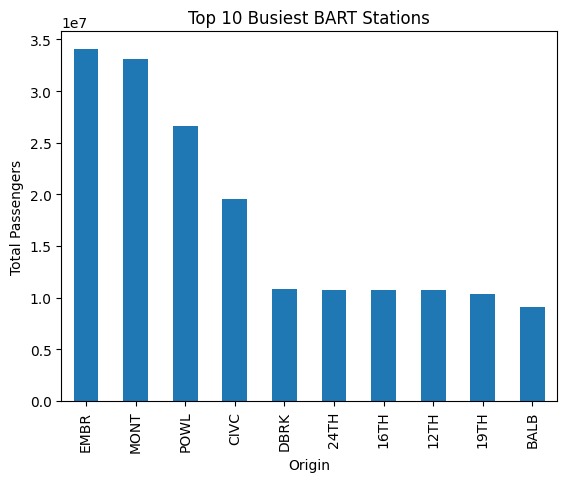

In [13]:
# Plot top 10 busiest stations
total_traffic.nlargest(10).plot(
    kind='bar', ylabel='Total Passengers', title='Top 10 Busiest BART Stations'
)

plt.show()

#### What is the least popular BART route?

In [14]:
# Group by Origin-Destination pairs and sum passenger count
route_traffic = df.groupby(['Origin', 'Destination'])['Throughput'].sum()

# Find the route with the lowest ridership
least_used_route = route_traffic.idxmin()
lowest_volume = route_traffic.min()

least_used_route, lowest_volume

(('WSPR', 'SBRN'), 40)

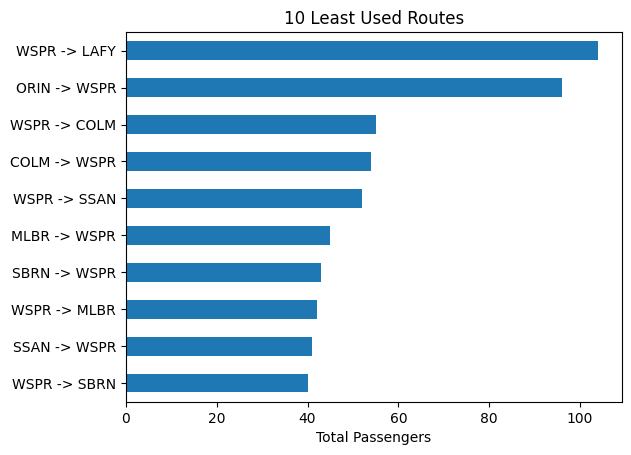

In [15]:
# Get 10 least used routes and format index labels
bottom_10 = route_traffic.nsmallest(10)
bottom_10.index = [f"{origin} -> {dest}" for origin, dest in bottom_10.index]

# Plot horizontal bar chart
bottom_10.plot(kind='barh', xlabel='Total Passengers', title='10 Least Used Routes')
plt.show()

### When is the best time to go to SF from Berkeley if you want to find a seat?

In [16]:
# Filter for Berkeley-to-SF bound travel
berkeley_stations = ['DBRK', 'NBRK', 'BKLY']
sf_stations = ['EMBR', 'MONT', 'POWL', 'CIVC']

sf_bound = df[
    (df['Origin'].isin(berkeley_stations)) & 
    (df['Destination'].isin(sf_stations))
]

# Calculate both average and total hourly traffic
hourly_summary = sf_bound.groupby('Hour')['Throughput'].agg(
    Avg_Throughput='mean',
    Total_Throughput='sum'
).reset_index().sort_values('Hour')

hourly_summary

,Hour,Avg_Throughput,Total_Throughput
0,0,5.644164,12959
1,1,2.763211,2719
2,2,3.000000,42
3,3,2.714286,19
4,4,1.612054,1899
5,5,5.667933,14918
6,6,17.493041,56555
7,7,49.386103,163468
8,8,93.500640,365120
9,9,98.538481,385384


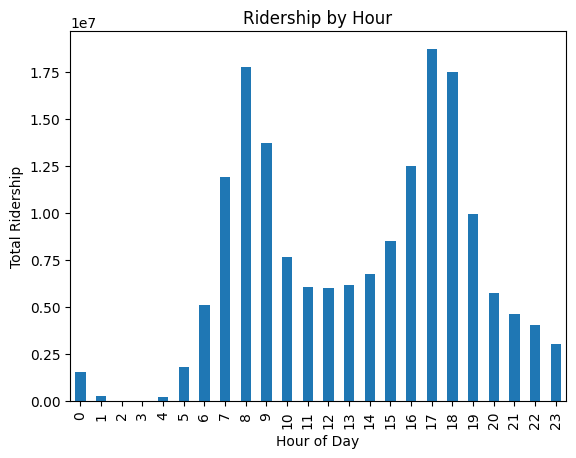

In [17]:
# Group by hour and plot total ridership
df.groupby('Hour')['Throughput'].sum().plot(
    kind='bar', xlabel='Hour of Day', ylabel='Total Ridership', title='Ridership by Hour'
)

plt.show()

### Which day of the week is the busiest?

In [18]:
# Group by day to get total and average throughput
daily_summary = df.groupby('Day Name')['Throughput'].agg(
    Total_Throughput='sum',
    Avg_Throughput='mean'
).sort_values('Total_Throughput', ascending=False).reset_index()
daily_summary

,Day Name,Total_Throughput,Avg_Throughput
0,Wednesday,30677189,14.983098
1,Tuesday,30350159,14.935881
2,Thursday,30049974,14.849635
3,Friday,28373709,13.807171
4,Monday,26967803,13.753287
5,Saturday,13696288,8.075613
6,Sunday,9602140,6.530837


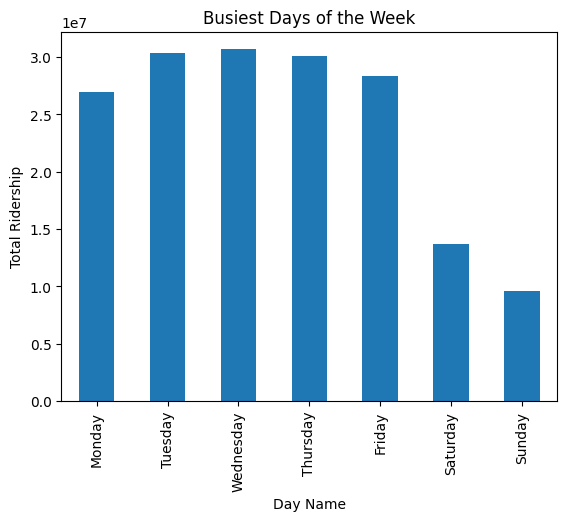

In [19]:
# Group by day and plot sorted total ridership
df.groupby('Day Name')['Throughput'].sum().loc[
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
].plot(kind='bar', ylabel='Total Ridership', title='Busiest Days of the Week')

plt.show()

### How many people take the BART late at night?

In [20]:
# Late-night (21:00-23:00) total and hourly breakdown
df[df['Hour'] >= 21].groupby('Hour')['Throughput'].agg(
    Total='sum', Avg='mean'
)

,Total,Avg
Hour,,
21,4644451,7.433358
22,4026424,6.838124
23,3023144,6.064104


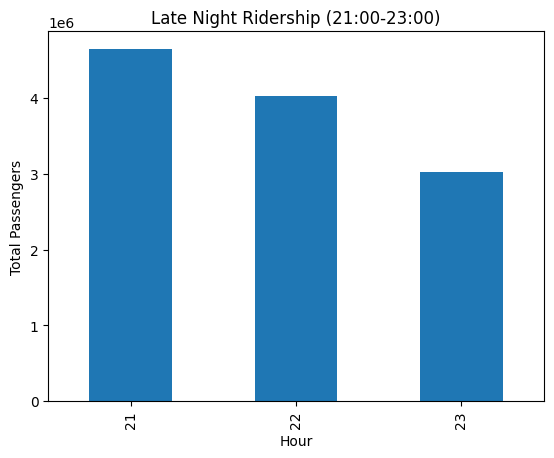

In [21]:
# Late night ridership graph (21:00-23:00)
df[df['Hour'] >= 21].groupby('Hour')['Throughput'].sum().plot(
    kind='bar', xlabel='Hour', ylabel='Total Passengers', title='Late Night Ridership (21:00-23:00)'
)
plt.show()

### Data Science Questions

#### Question A
Compute the straight line distance between every station.

#### Question B
Build a model that can predict the number of people commuting to work by BART between any 2 stations:
- How would you approach that?
- What additional data would you need?
- How would you want the city or BART officials to use your data?

In [22]:
df2.head()

,Abbreviation,Description,Location,Name
0,12TH,"1245 Broadway, Oakland CA 94612<br />12th St. ...","-122.271450,37.803768,0",12th St. Oakland City Center (12TH)
1,16TH,"2000 Mission Street, San Francisco CA 94110<br...","-122.419694,37.765062,0",16th St. Mission (16TH)
2,19TH,"1900 Broadway, Oakland CA 94612<br />19th Stre...","-122.268602,37.808350,0",19th St. Oakland (19TH)
3,24TH,"2800 Mission Street, San Francisco CA 94110<br...","-122.418143,37.752470,0",24th St. Mission (24TH)
4,ASHB,"3100 Adeline Street, Berkeley CA 94703<br />As...","-122.270062,37.852803,0",Ashby (ASHB)


In [23]:
df2.drop(['Description', 'Name'], axis=1, inplace=True)

In [24]:
# Split the 'Location' column into Longitude, Latitude, and Altitude, and convert to float
df2[['Longitude', 'Latitude', 'Altitude']] = df2['Location'].str.split(',', expand=True).astype(float)

# Drop the unnecessary 'Altitude' and original 'Location' columns
df2 = df2.drop(columns=['Altitude', 'Location'])

In [25]:
df2.head()

,Abbreviation,Longitude,Latitude
0,12TH,-122.271450,37.803768
1,16TH,-122.419694,37.765062
2,19TH,-122.268602,37.808350
3,24TH,-122.418143,37.752470
4,ASHB,-122.270062,37.852803


### Compute the straight line distance between every station.

In [26]:
from sklearn.metrics.pairwise import haversine_distances

# 1. BART Station Coordinates
stations = {
    'DBRK': (37.8701, -122.2681), 'NBRK': (37.8740, -122.2834),
    'BKLY': (37.8701, -122.2681), 'EMBR': (37.7929, -122.3967),
    'MONT': (37.7894, -122.4011), 'POWL': (37.7845, -122.4080),
    'CIVC': (37.7795, -122.4138)
}

# 2. Convert coordinates to radians
coords_df = pd.DataFrame.from_dict(stations, orient='index', columns=['lat', 'lon'])
coords_rad = np.radians(coords_df[['lat', 'lon']])

# 3. Pairwise straight-line distance matrix (km)
dist_km = pd.DataFrame(
    haversine_distances(coords_rad) * 6371,
    index=coords_df.index,
    columns=coords_df.index
)

dist_km

,DBRK,NBRK,BKLY,EMBR,MONT,POWL,CIVC
DBRK,0.000000,1.411246,0.000000,14.186145,14.729708,15.542650,16.286678
NBRK,1.411246,0.000000,1.411246,13.428643,13.976526,14.791693,15.543051
BKLY,0.000000,1.411246,0.000000,14.186145,14.729708,15.542650,16.286678
EMBR,14.186145,13.428643,14.186145,0.000000,0.548589,1.363247,2.116191
MONT,14.729708,13.976526,14.729708,0.548589,0.000000,0.815185,1.567624
POWL,15.542650,14.791693,15.542650,1.363247,0.815185,0.000000,0.754269
CIVC,16.286678,15.543051,16.286678,2.116191,1.567624,0.754269,0.000000


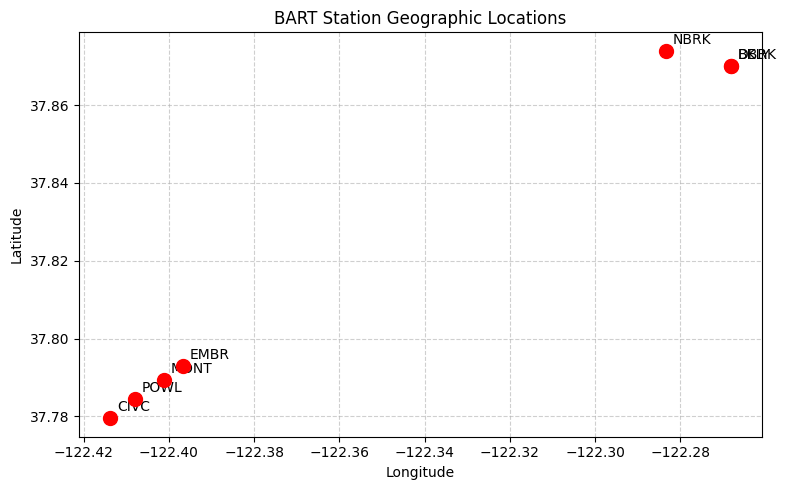

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Define station coordinates
stations = {
    'DBRK': (37.8701, -122.2681), 'NBRK': (37.8740, -122.2834),
    'BKLY': (37.8701, -122.2681), 'EMBR': (37.7929, -122.3967),
    'MONT': (37.7894, -122.4011), 'POWL': (37.7845, -122.4080),
    'CIVC': (37.7795, -122.4138)
}
station_coords = pd.DataFrame.from_dict(stations, orient='index', columns=['lat', 'lon'])

# 2. Plot geographic locations
plt.figure(figsize=(8, 5))
plt.scatter(station_coords['lon'], station_coords['lat'], color='red', s=100, zorder=5)

for station, row in station_coords.iterrows():
    plt.annotate(station, (row['lon'], row['lat']), textcoords="offset points", xytext=(5, 5), ha='left')

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("BART Station Geographic Locations")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [28]:
d = {
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6,
    "Sunday": 7,
}

In [29]:
df['Day Name']=df['Day Name'].map(d)

In [30]:
df.head()

,Origin,Destination,Throughput,Year,Month,Day,Day Name,Hour
0,12TH,12TH,1,2016,1,1,5,0
1,12TH,16TH,1,2016,1,1,5,0
2,12TH,24TH,4,2016,1,1,5,0
3,12TH,ASHB,4,2016,1,1,5,0
4,12TH,BALB,2,2016,1,1,5,0


In [31]:
# Group the data by Hour, Origin station, Destination station, and Day name; aggregate total passenger count (Throughput) for each breakdown
df_grouped = (
    df.groupby(["Hour", "Origin", "Destination", "Day Name"])
    .agg({"Throughput": "sum"})
    .reset_index()
)

In [32]:
x = df_grouped.drop(columns=["Throughput"])
y = df_grouped["Throughput"]

In [33]:
x=pd.get_dummies(x,drop_first=True)

In [34]:
df.head()

,Origin,Destination,Throughput,Year,Month,Day,Day Name,Hour
0,12TH,12TH,1,2016,1,1,5,0
1,12TH,16TH,1,2016,1,1,5,0
2,12TH,24TH,4,2016,1,1,5,0
3,12TH,ASHB,4,2016,1,1,5,0
4,12TH,BALB,2,2016,1,1,5,0


In [35]:
x.shape

(301922, 92)

In [36]:
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Model
model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model.fit(x_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [37]:
tahmin=model.predict(x_test)

In [38]:
from sklearn.metrics import r2_score,mean_squared_error

In [39]:
r2_score(y_test,tahmin)

0.7371248006820679

In [40]:
from sklearn.tree import DecisionTreeRegressor

In [41]:
dt=DecisionTreeRegressor()

In [42]:
dt.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [43]:
tahmindt=dt.predict(x_test)

In [44]:
r2_score(y_test,tahmindt)

0.9618867130166439

In [45]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

In [46]:
R=Ridge()

In [47]:
L=Lasso()

In [48]:
E=ElasticNet()

In [49]:
R.fit(x_train,y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [50]:
tahmin2=R.predict(x_test)

In [51]:
r2_score(y_test,tahmin2)

0.17233744516241623

In [52]:
L.fit(x_train,y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [53]:
tahmin3=L.predict(x_test)

In [54]:
r2_score(y_test,tahmin3)

0.16967861130505557

In [55]:
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor

In [56]:
ETR = ExtraTreesRegressor()

In [57]:
GBR = GradientBoostingRegressor()

In [58]:
ada = AdaBoostRegressor()

In [59]:
ETR.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [60]:
tahmin4=ETR.predict(x_test)

In [61]:
r2_score(y_test,tahmin4)

0.9653129508363236

In [62]:
GBR.fit(x_train,y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [63]:
tahmin5=GBR.predict(x_test)

In [64]:
r2_score(y_test,tahmin5)

0.4491227689659285

In this project, we answered all required Data Analysis and Data Science questions. After training various models, we achieved our highest performance with ExtraTreesRegressor, reaching an $R^2$ score of 96.53%.